# Práctica 3.1: Regresión lineal

<center><h3>
    Pablo Pardo Cotos
</h3></center>

## Instrucciones

Esto es un **Jupyter Notebook**, un documento que integra código Python en un archivo Markdown.
Esto nos permite ir ejecutando celdas de código poco a poco, así como generar automáticamente un informe bien formateado de la práctica.

Puedes añadir una celda con el botón **"Insert"** de la barra de herramientas, y cambiar su tipo con **"Cell > Cell Type"**

Para ejecutar una celda de código, la seleccionaremos y pulsaremos el botón **"▶ Run"** de la barra de herramientas.
Para pasar el documento a HTML, seleccionaremos **"File > Download as > HTML (.html)"**

Sigue este guion hasta el final. Ejecuta el código proporcionado paso a paso comprendiendo lo que estás haciendo y reflexionando sobre los resultados. Habrá preguntas intercaladas a lo largo del guion, responde a todas ellas en la sección reservada para ese fin: **"Respuestas al cuestionario"**. Por favor, no modifiques ninguna línea de código salvo cuando se te pida explícitamente.

No olvides insertar tu **nombre y apellidos** en la celda superior.

## Entrega de la práctica

La fecha límite de entrega será la indicada en el Campus Virtual. La entrega consistirá en un único archivo comprimido con el nombre `APELIDOS_NOME_RegresionLineal.zip` que contenga los siguientes ficheros:

 * `APELIDOS_NOME_RegresionLineal.html`: Archivo HTML fruto de la exportación del presente Notebook, con las preguntas respondidas al final del documento.
 * `APELIDOS_NOME_RegresionLineal.ipynb`: Archivo Jupyter Notebook fuente.
 * Archivo de datos del problema de libre elección.

## Números aleatorios

<span style="color:red">**MUY IMPORTANTE:**</span> Vamos a establecer un *seed* con un valor predefinido inmediatamente antes de ejecutar cualquier operación con un componente aleatorio. Así nos aseguraremos de que nuestros resultados sean repetibles.

Esto es, vamos a poner `np.random.seed(SEED_VALUE)` antes de:
 - `train_test_split()`
 - `fit()`
 - `predict()`

También vamos a poner `random_state=SEED_VALUE` en aquellas funciones que lo admitan (como `train_test_split`).

Habrá ocasiones en las que esto sea excesivo, pero así nos curamos en salud ante despistes.

# Estimación del precio de las viviendas

En este ejercicio vamos a asentar los conceptos vistos en las clases teóricas relativos a la técnica de regresión lineal a través de un problema sencillo. Supongamos que somos una inmobiliaria y queremos desarrollar una herramienta que nos ayude a estimar un precio recomendado de venta de nuestros inmuebles. Disponemos de un pequeño dataset, `vivendas.csv`, que recoge datos de 73 viviendas vendidas por la empresa en los dos últimos años. En este conjunto de datos tenemos registrada la superficie total del inmueble en metros cuadrados, junto con el precio de venta en miles de euros. Nuestro objetivo final es ser capaces de, para cada nuevo inmueble a la venta, obtener un precio recomendado de venta en base a los metros cuadrados de los que dispone.

## Carga de datos y comprensión de los mismos

Comenzaremos por cargar en Python nuestro conjunto de datos. Lo primero que debemos hacer es asegurarnos de tener el archivo de datos en el mismo directorio que este guion de prácticas.

Para la carga de los datos empleamos la función `read_csv()` indicando el nombre del archivo CSV. También detallamos que la primera línea del archivo contiene los nombres de las columnas (`header = 0`) y que los datos están separados por comas (`delimiter = ','`). Ejecuta el siguiente script pulsando el botón **"▶ Run"** de la barra de herramientas:

In [167]:
import pandas as pd  # Importamos la librería (esto solo es necesario hacerlo una vez)

vivendas = pd.read_csv('vivendas.csv',  # Cargamos el csv
                       delimiter=',',
                       header=0)

El dataset ya se encuentra disponible en el entorno Python. Ahora podremos referenciarlo por medio del objeto `vivendas`, del tipo `DataFrame`. Los dataframes son una clase de objetos especial en Python, usados como la estructura de datos fundamental por la mayoría del software de construcción de modelos de este entorno. Un dataframe almacena una tabla de datos en la que cada fila corresponde a una instancia (en nuestro caso viviendas) y cada columna a una variable (superficie y precio).

Una buena práctica antes de comenzar a construir un modelo de regresión es analizar y comprender los datos con los que vamos a trabajar. Lo primero que haremos, no obstante, será obtener una breve descripción de los mismos:

* Número de instancias.
* Número de variables.
* Tipo de cada variable.
* Distribución de valores por cada variable.
* Correlación entre variables.

La función `.info()` del objeto `DataFrame` nos da una primera descripción de los datos bastante completa:

In [168]:
vivendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   superficie  73 non-null     int64  
 1   prezo       73 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 1.3 KB


Vemos una descripción por columnas, indicándonos el tipo de dato de cada columna y cuántos valores hay para cada una de ellas. Hay otras alternativas a la función anterior. Por ejemplo, `.head()` también nos muestra las primeras *n* instancias de nuestro conjunto de datos:

In [169]:
vivendas.head(n=6)

,superficie,prezo
0,81,191.73
1,117,286.90
2,99,248.93
3,85,143.29
4,116,249.61
5,105,91.31


Con `.shape` conocemos directamente el número de filas y columnas del dataset: 

In [170]:
vivendas.shape

(73, 2)

In [171]:
print('Filas: {}'.format(vivendas.shape[0]))
print('Columnas: {}'.format(vivendas.shape[1]))

Filas: 73
Columnas: 2


Un consejo útil para el futuro: cuando tengas dudas sobre qué hace o qué argumentos toma una función, no dudes en consultar la ayuda de Python con `help()`. Por ejemplo:

In [172]:
help(vivendas.head)

Help on method head in module pandas.core.generic:

head(n: 'int' = 5) -> 'Self' method of pandas.DataFrame instance
    Return the first `n` rows.

    This function exhibits the same behavior as ``df[:n]``, returning the
    first ``n`` rows based on position. It is useful for quickly checking
    if your object has the right type of data in it.

    When ``n`` is positive, it returns the first ``n`` rows. For ``n`` equal to 0,
    it returns an empty object. When ``n`` is negative, it returns
    all rows except the last ``|n|`` rows, mirroring the behavior of ``df[:n]``.

    If ``n`` is larger than the number of rows, this function returns all rows.

    Parameters
    ----------
    n : int, default 5
        Number of rows to select.

    Returns
    -------
    same type as caller
        The first `n` rows of the caller object.

    See Also
    --------
    DataFrame.tail: Returns the last `n` rows.

    Examples
    --------
    >>> df = pd.DataFrame(
    ...     {
    ...  

> ❓ **_Pregunta 1._**  Indica el número de instancias y variables del dataset y su tipo. Investiga cómo acceder a valores de filas y columnas concretas de un objeto dataframe y averigua cuál fue el precio de venta de la vivienda en la posición 50 del dataset. Indica el comando que empleaste para averiguarlo.

Hay **73 instancias** (viviendas) y **2 variables**: `superficie`, de tipo entero (`int64`), y `prezo`, de tipo decimal (`float64`). Ambas son numéricas y no tienen valores nulos.

Para acceder a filas y columnas concretas se puede usar `iloc` (por posición, empezando en 0) o `loc` (por la etiqueta del índice y el nombre de la columna). El precio de venta de la vivienda en la posición 50 es de **376,51 miles de euros** (376.510 €), obtenido con el comando:
```python
vivendas.iloc[50]['prezo']
```

También podemos analizar la distribución de los datos con la función `.describe()`:

In [173]:
vivendas.describe()

,superficie,prezo
count,73.000000,73.000000
mean,127.534247,162.652192
std,52.721512,108.200288
min,75.000000,51.250000
25%,91.000000,89.520000
50%,109.000000,119.730000
75%,138.000000,191.730000
max,281.000000,507.090000


> ❓ **_Pregunta 2._**  ¿Cuál es el precio medio de venta de los inmuebles? ¿Qué indican y significan *25%.*, *50%.* y *75%.* en la salida de la función anterior? Basándote en los valores anteriores, ¿cuál es la mediana de superficie y la de precio?

El precio medio de venta de los inmuebles es de **162,65 miles de euros** (`mean`).

Los valores 25%, 50% y 75% son los cuartiles: si ordenamos los valores de una variable de menor a mayor, indican el valor por debajo del cual queda ese porcentaje de los datos. El 25% es el primer cuartil (una cuarta parte de las viviendas está por debajo), el 50% es la mediana, es decir, el valor central que deja la mitad de los datos por debajo y la otra mitad por encima, y el 75% es el tercer cuartil (tres cuartas partes de los datos quedan por debajo y solo el 25% por encima).

La mediana de la superficie es **109 m²** y la del precio, **119,73 miles de euros**.

Con la función `.plot()` podemos dibujar rápidamente un *scatter plot*, o gráfico de dispersión, de nuestros datos:

<Axes: xlabel='superficie', ylabel='prezo'>

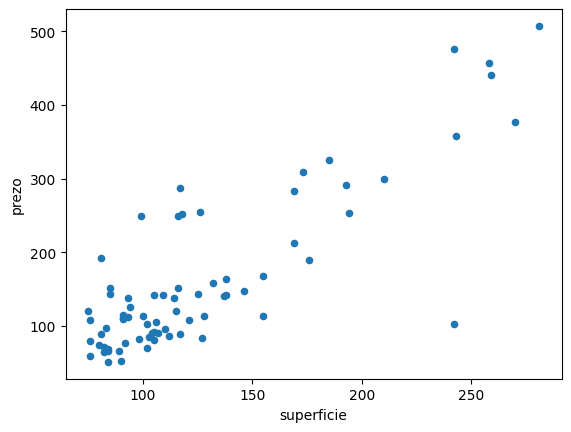

In [174]:
vivendas.plot(kind='scatter', x='superficie', y='prezo')

> ❓ **_Pregunta 3._**  Observa detenidamente el gráfico anterior. Ya que se trata de un gráfico de dispersión, ¿qué podrías comentar sobre la dispersión de los datos? ¿Dirías que existe algún tipo de relación entre las dos variables? Justifica tu respuesta.

Sí, hay relación entre las dos variables, y es **lineal y positiva**: los puntos suben de izquierda a derecha, así que las viviendas más grandes suelen ser más caras. A grandes rasgos, el precio sube entre 1,6 y 2 miles de euros por cada metro cuadrado más.

Los datos no están repartidos por igual. La mayoría de las viviendas son pequeñas (entre 75 y 150 m²) y baratas (entre 50 y 170 miles de euros), y ahí los puntos están bastante juntos. Las viviendas grandes son pocas y sus precios varían mucho más. Además, algunos puntos no siguen la tendencia, como una vivienda de 242 m² que cuesta solo 102,9 miles de euros, o algunas de unos 100-125 m² que cuestan entre 250 y 290 miles de euros.

Los puntos no forman una recta perfecta, pero la relación es fuerte, como confirma la correlación de 0,83 que se calcula más adelante.

Los gráficos de dispersión nos ayudan a visualizar relaciones lineales entre la variable a predecir y las variables predictoras. En este caso queremos predecir el precio del inmueble y la única variable predictora de la que disponemos es su superficie pero, si dispusiésemos de varias variables predictoras, deberíamos dibujar un gráfico de dispersión para cada una de ellas o un gráfico en 3 dimensiones en el caso de que sean 2 variables predictoras.

Para representaciones de este tipo, es conveniente emplear la librería `matplotlib`.

In [175]:
import matplotlib.pyplot as plt  # Importamos la librería (esto solo es necesario hacerlo una vez)
import numpy as np  # Importamos NumPy, para operaciones matemáticas

x  = [0.         0.04081633 0.08163265 0.12244898 0.16326531]...
y1 = [1.         0.96729486 0.8713187  0.71834935 0.51839257]...
y2 = [-1.         -0.99179001 -0.96729486 -0.92691676 -0.8713187 ]...


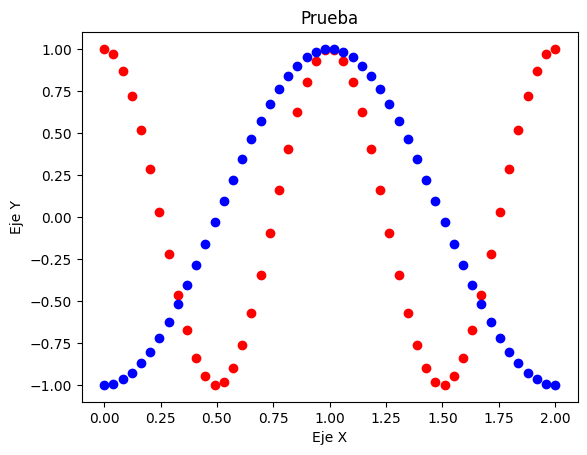

In [176]:
# Simulamos unos datos
x = np.linspace(0.0, 2.0)
y1 = np.cos(2 * np.pi * x)
y2 = np.cos(np.pi + np.pi * x)

print('x  = {}...'.format(x[:5]))
print('y1 = {}...'.format(y1[:5]))
print('y2 = {}...'.format(y2[:5]))


# Dibujamos los datos
fig = plt.figure()  # Creamos una figura (contenedor para elementos a dibujar)
ax = fig.add_subplot(111, projection='rectilinear')  # Añadimos un Axes a la figura (contiene los elementos del dibujo)

ax.scatter(x, y1, color="red")  # Añadimos un scatterplot rojo
ax.scatter(x, y2, color="blue")  # Añadimos un scatterplot azul

ax.set_title("Prueba")  # Ponemos un título

plt.xlabel("Eje X")  # Nombramos los ejes
plt.ylabel("Eje Y")

plt.show()  # Mostramos la figura por pantalla

Analizando el gráfico de dispersión de las viviendas ya nos pudimos hacer una idea de la dependencia entre las dos variables. Otra forma de analizar esta dependencia es estudiando su correlación. La correlación es una medida estadística que muestra el grado de dependencia lineal entre dos variables. Esta medida puede tomar valores en el rango [-1, +1]:

* Si el valor de una de las variables crece de forma constante conforme aumenta el valor de la otra, entonces decimos que tienen una fuerte correlación positiva (valores próximos a +1).
* Si el valor de una de las variables disminuye de forma constante cuando el valor de la otra aumenta, entonces tienen una fuerte correlación negativa (valores próximos a -1).
* Si las dos variables están poco relacionadas entonces obtenemos valores próximos a 0.

En Python podemos obtener el coeficiente de correlación empleando la función `.corr()` de una columna del dataframe sobre la otra columna:

In [177]:
vivendas['superficie'].corr(vivendas['prezo'])

np.float64(0.8337718450638251)

Observa cómo accedemos a cada una de las columnas del dataframe.

Si trabajásemos con más de 2 variables resultaría más sencillo invocar la función `.corr()` directamente sobre el dataframe, para obtener una matriz de correlaciones entre cada par de variables:

In [178]:
vivendas.corr()

,superficie,prezo
superficie,1.000000,0.833772
prezo,0.833772,1.000000


## Construcción de un modelo de regresión a bajo nivel

Vamos a construir un regresor lineal empleando el método de descenso del gradiente que ya vimos en las clases expositivas. En este caso vamos a emplear las dos variables de las que disponemos directamente, pero ten en cuenta que habitualmente antes de entrenar un modelo se realiza una etapa de preprocesado en la que, entre otras cosas, seleccionamos las instancias y las variables que queremos emplear en el aprendizaje.

Queremos obtener una función lineal $h_\theta (x)$ (una recta) que, a partir de los valores de superficie de las viviendas, $x$, nos prediga su precio más adecuado, $y$:
  $$ y = h_\theta (x) = \theta_0 + \theta_1 x, $$
donde $\theta_0$ y $\theta_1$ son los 2 parámetros que definen la recta.

Definimos la función $h_\theta (x)$ en Python:

In [179]:
### Función de regresión lineal h ###
def h(x, th0, th1):
    return (th0 + x * th1)

Con esta función $h_\theta (x)$, si conociésemos los valores óptimos de los dos parámetros $\theta_0$ y $\theta_1$ de la recta, seríamos capaces de predecir un precio aproximado ($y$) en base a una superficie dada ($x$). Por ejemplo, imagina que  $\theta_0 = 0.5$ y $\theta_1 = 3$ son los valores óptimos de la recta. Si tenemos una vivienda de 242 metros cuadrados (vivienda 24 en el dataset), podemos estimar su precio así:

In [180]:
h(x=242, th0=0.5, th1=3)

726.5

El precio estimado para una vivienda de 242 metros cuadrados sería de 726500 euros. Sin embargo, el precio real de esta vivienda es:

In [181]:
vivendas.iloc[23]

superficie    242.0
prezo         475.4
Name: 23, dtype: float64

La estimación supera el precio real del inmueble.

El problema es por tanto que no conocemos cuáles son los valores reales de los parámetros, necesitamos aprenderlos. Para ello, definimos una función de coste $J(\theta_0, \theta_1)$ que guíe al algoritmo de aprendizaje en el ajuste de $\theta_0$ y $\theta_1$. Empleamos el error cuadrático medio:

In [182]:
### Error cuadrático medio ###
def ecm(reais, predicion):
    m = len(reais)  # tamaño del conjunto de datos
    erro = sum((predicion - reais)**2) / (2*m)
    return erro

### Función de coste J ###
def j(x, y, th0, th1):
    pred = h(x, th0, th1)  # predicción realizada con nuestro regresor lineal h
    erro = ecm (y, pred)
    return erro

Por último, creamos una función que implemente el descenso del gradiente, método que nos permitirá ajustar la recta que mejor aproxima la nube de puntos:

In [183]:
### Implementación del método del descenso del gradiente ###
def desc_grad(x, y, alpha=0.00001, iteracions=35):
    # Inicializamos los coeficientes a 0
    theta0 = 0
    theta1 = 0
    hist_custos = []

    for i in range(iteracions):
        # Calculamos el error cometido con la función de coste
        custo = j(x, y, theta0, theta1)
        hist_custos.append(custo)

        ## Actualizamos los valores de los coeficientes theta0 y theta1
        pred = h(x, theta0, theta1)  # predicción realizada con nuestro regresor lineal h
        m = len(x)                # tamaño del conjunto de datos
        theta0 = theta0 - alpha * sum(pred-y) / m
        theta1 = theta1 - alpha * sum((pred-y) * x) / m


        # Graficamos la iteración
        if i%2 == 0 or i == iteracions:  # Graficamos de 2 en 2 pasos
            fig = plt.figure(figsize=(20, 5))
            ax1 = fig.add_subplot(121, projection='rectilinear')
            ax2 = fig.add_subplot(122, projection='rectilinear')

            ax1.scatter(x, y, color="red")
            line_x_vals = np.array(ax1.get_xlim())
            line_y_vals = theta0 + theta1 * line_x_vals
            ax1.plot(line_x_vals, line_y_vals, '--')
            ax1.set_title("Iteración {}:     y = {} + {} * x".format(i, theta0, theta1))
            ax1.set_xlabel("precio")
            ax1.set_ylabel("superficie")

            ax2.plot(range(i+1), hist_custos, '--', color="green")
            ax2.set_title("Coste: {}".format(custo))
            ax2.set_xlabel("iteración")
            ax2.set_ylabel("coste")

            plt.show()

Ahora, simplemente llamamos a la función anterior pasándole como datos la superficie y el precio de las viviendas:

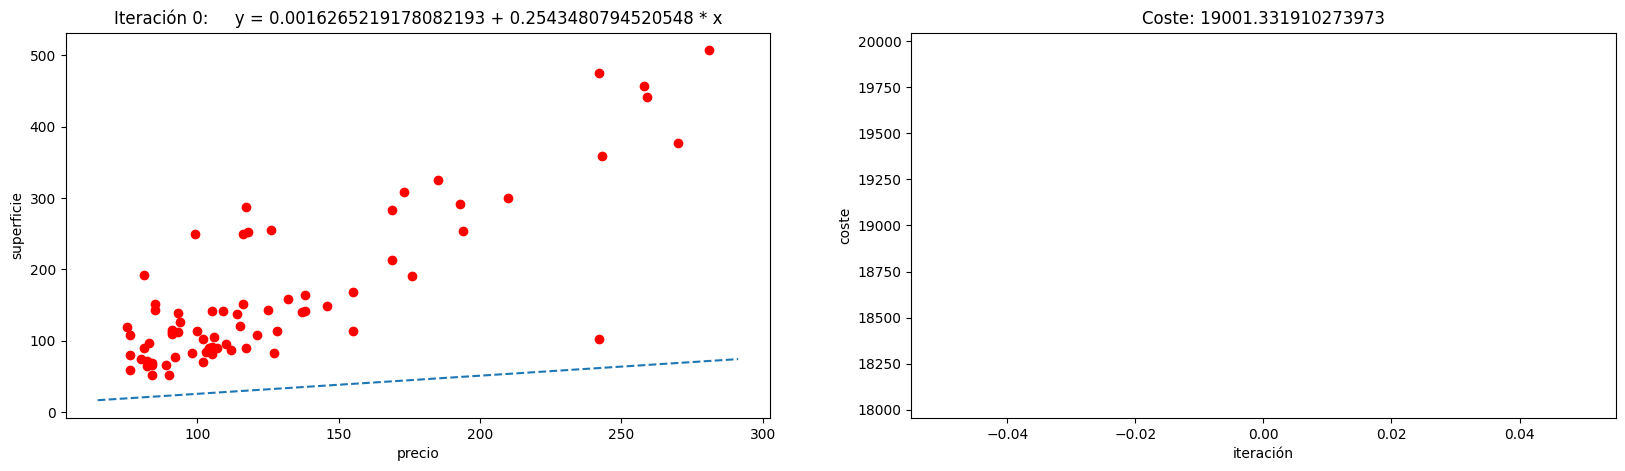

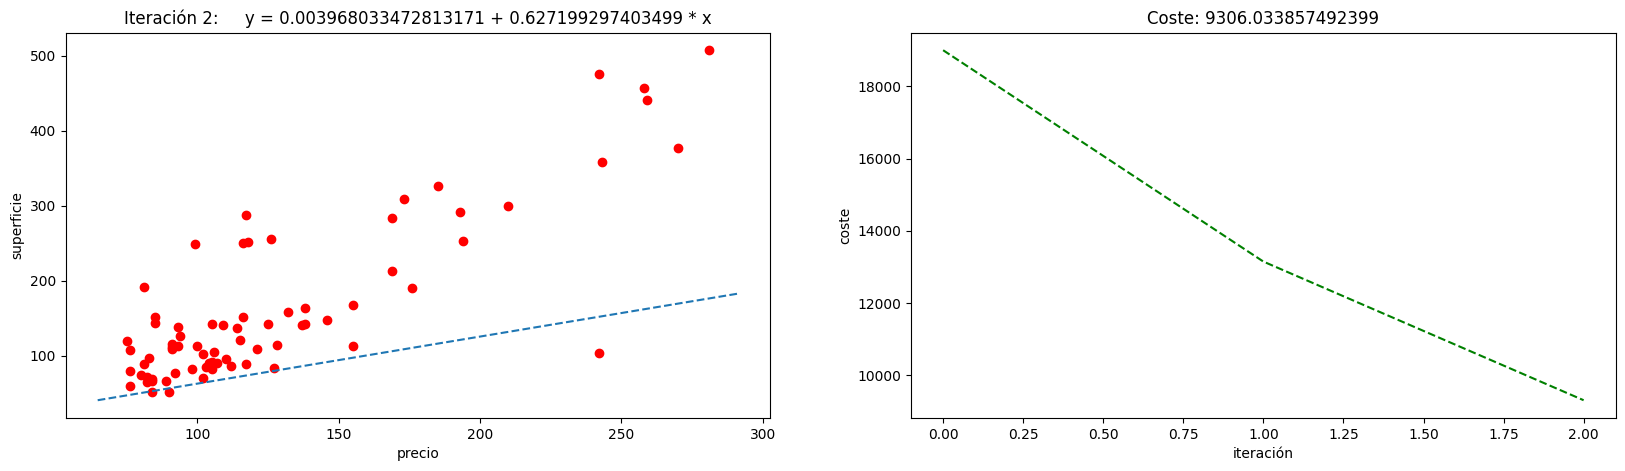

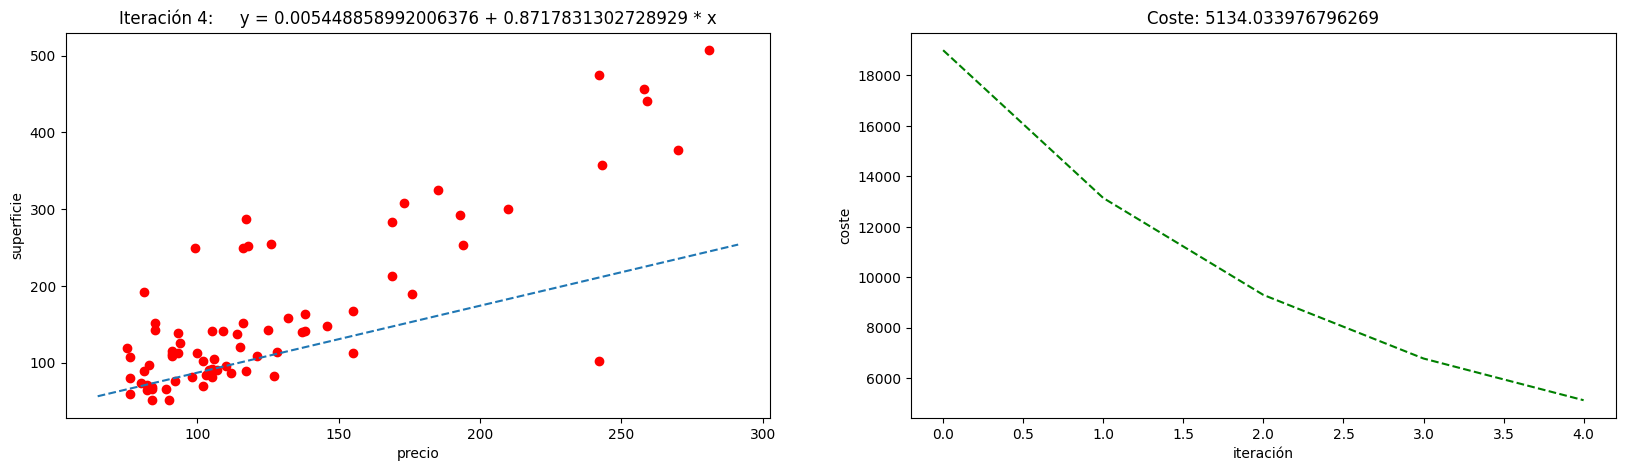

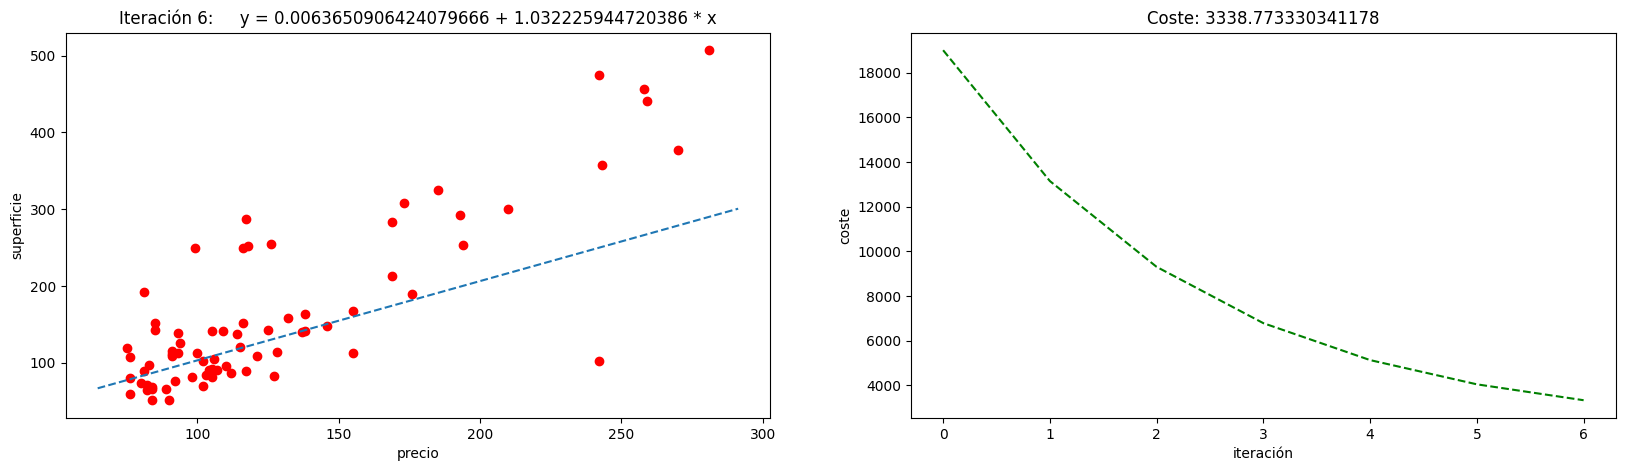

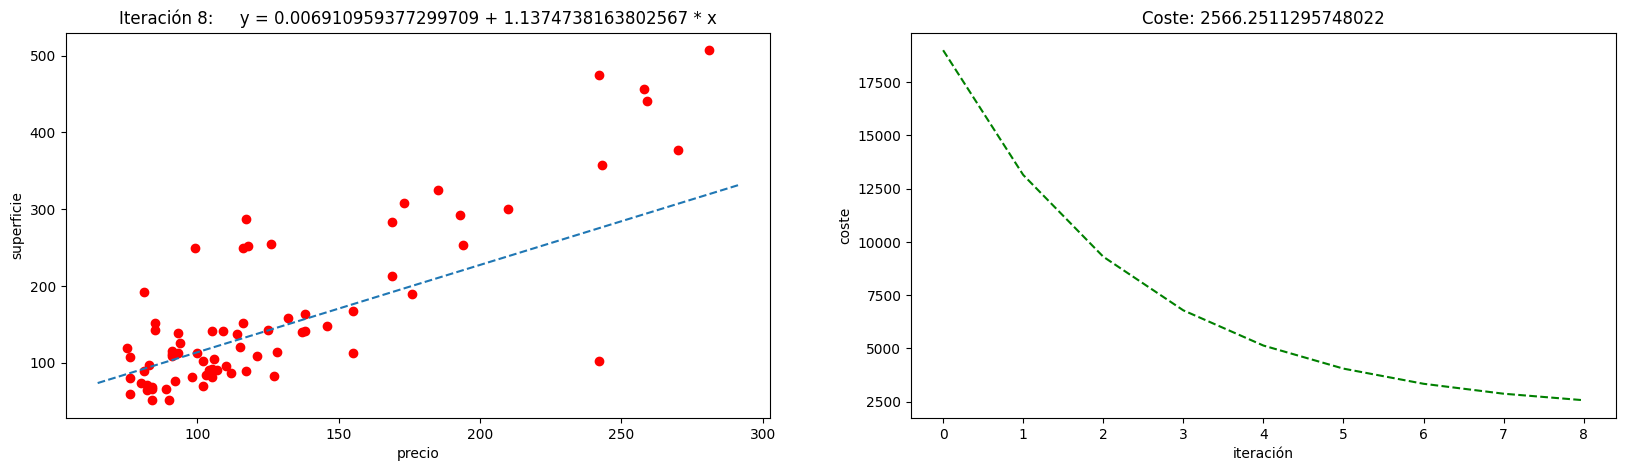

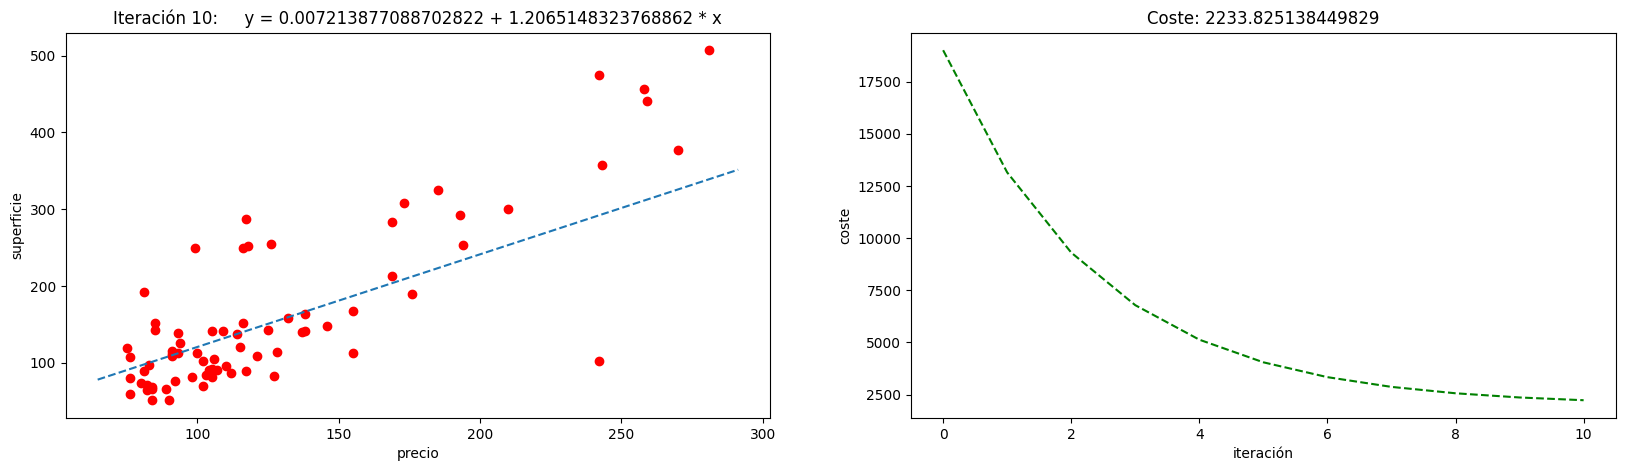

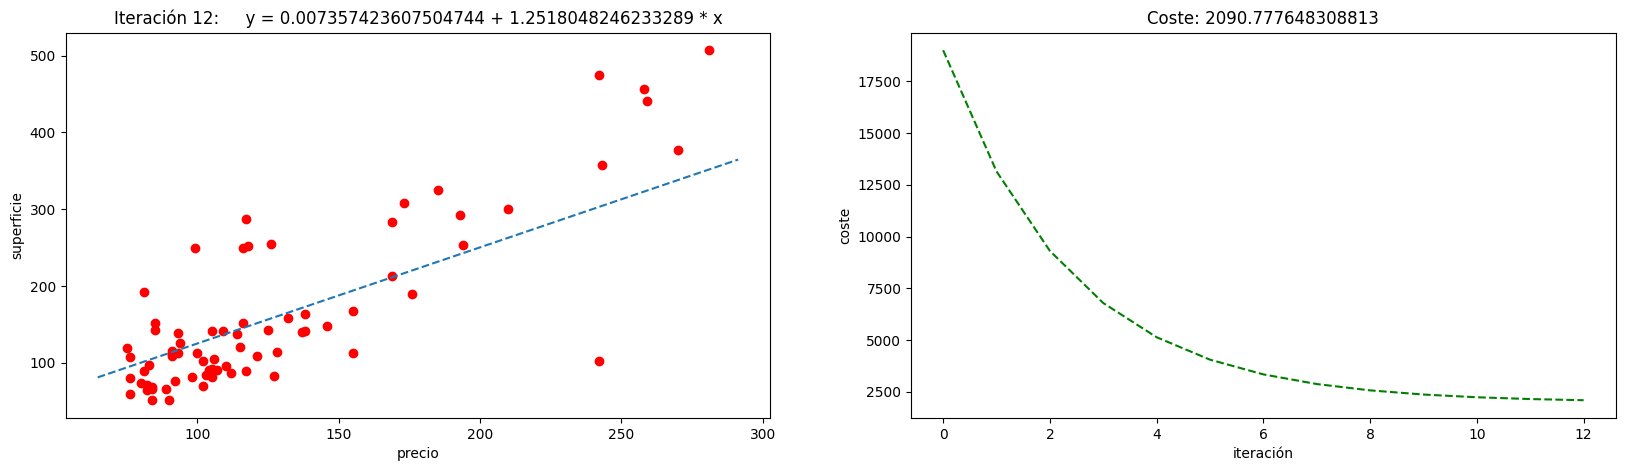

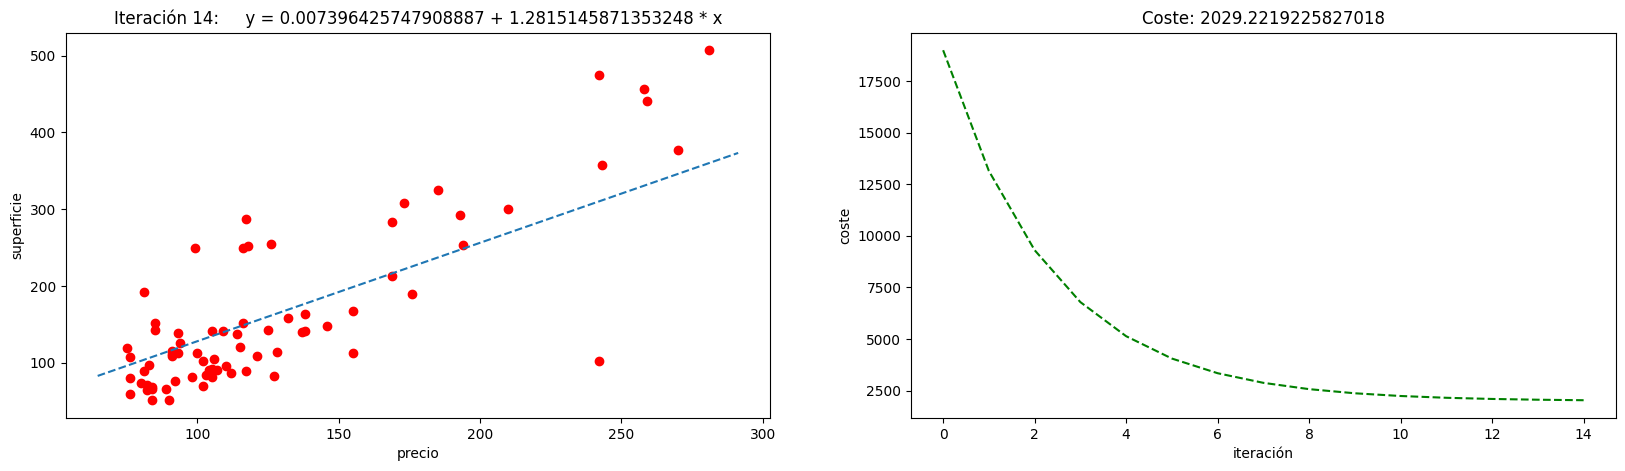

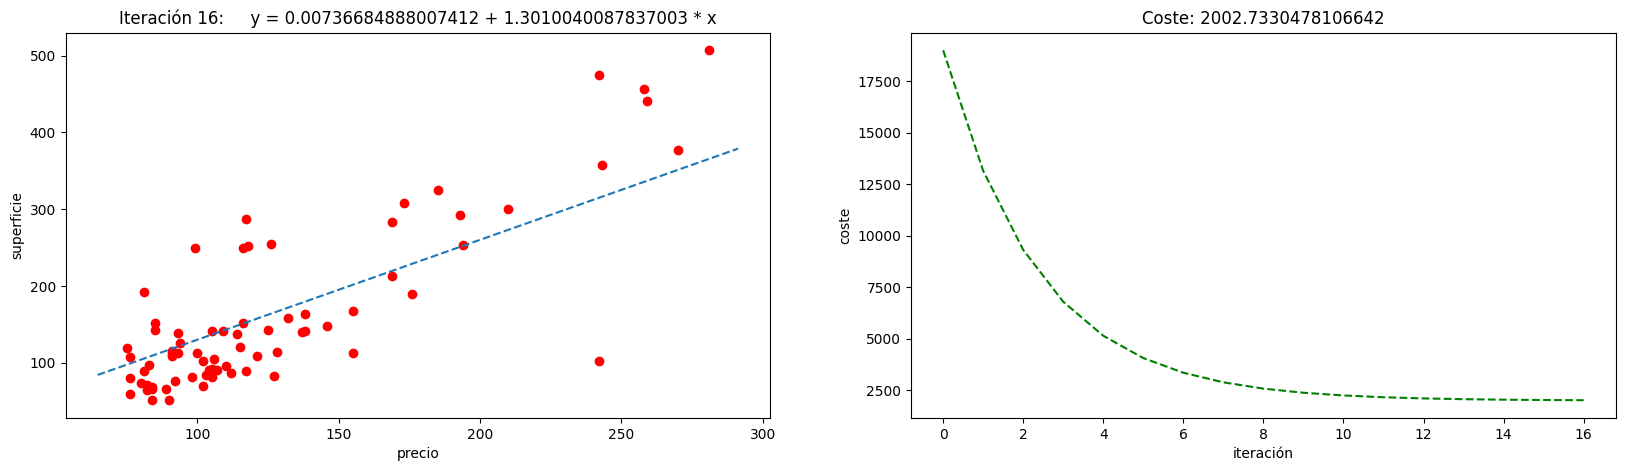

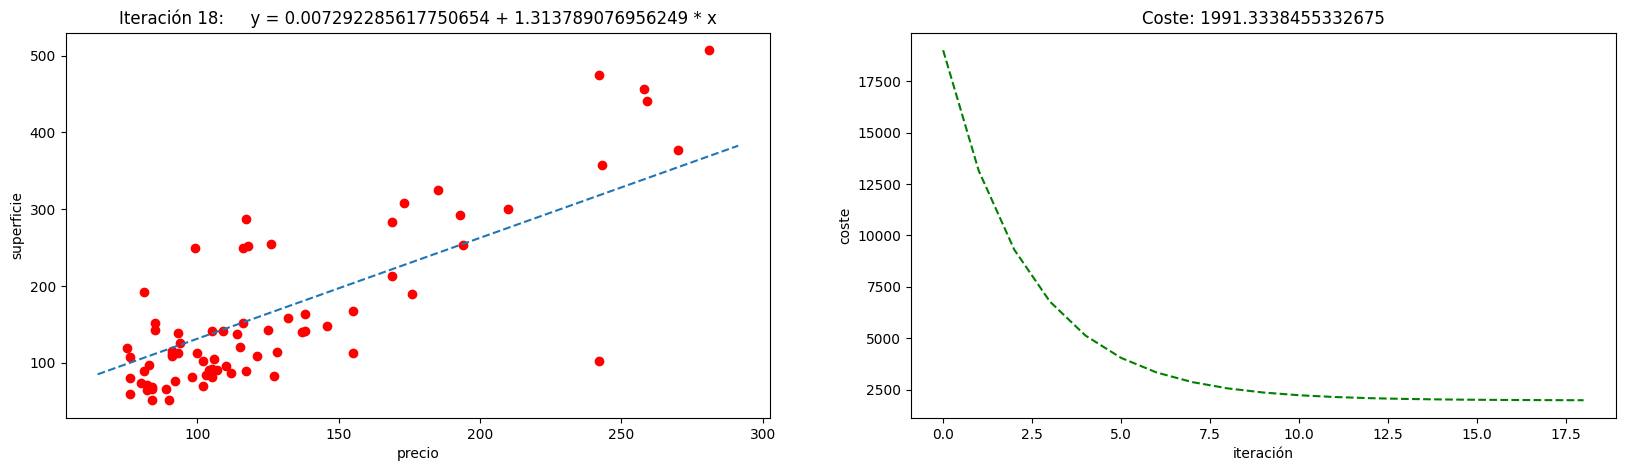

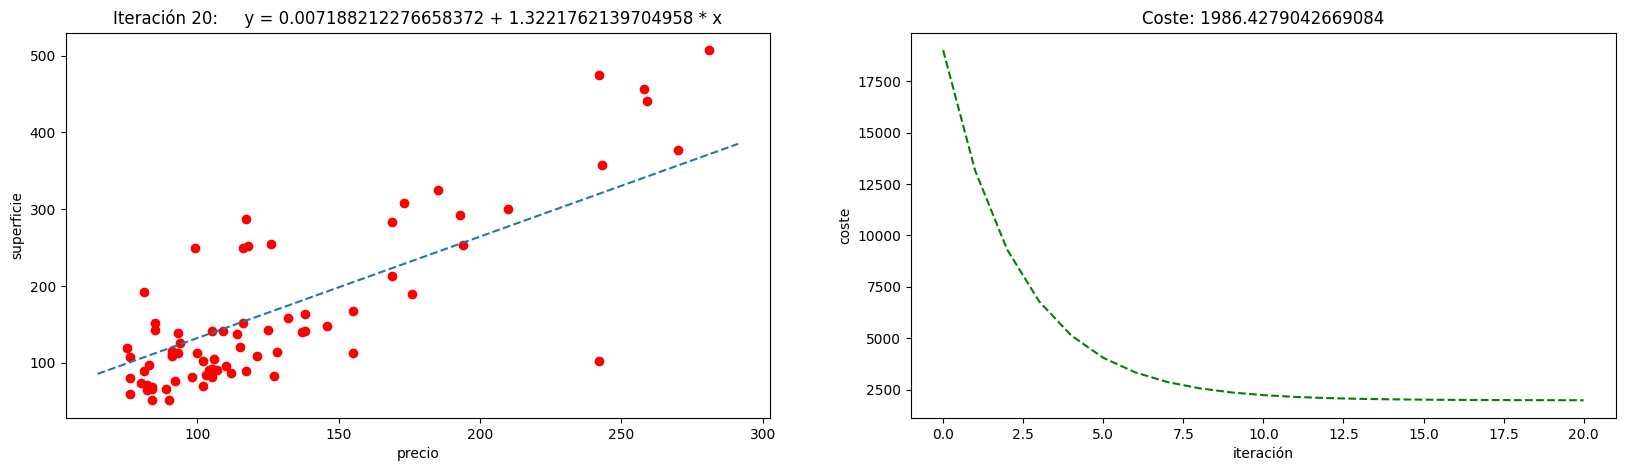

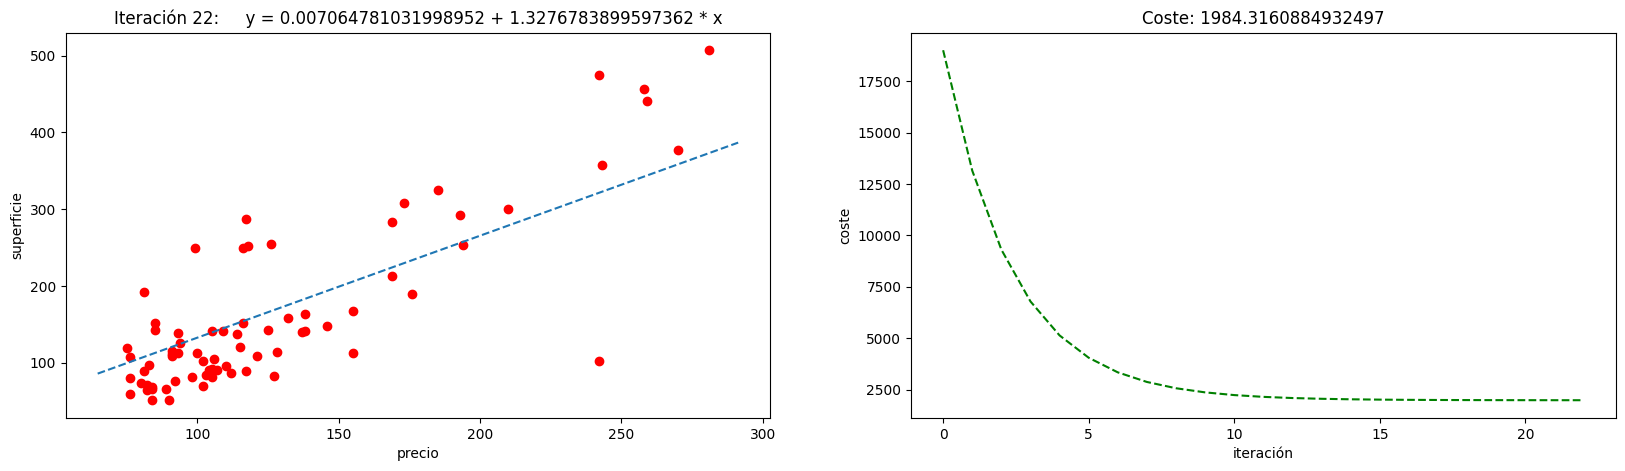

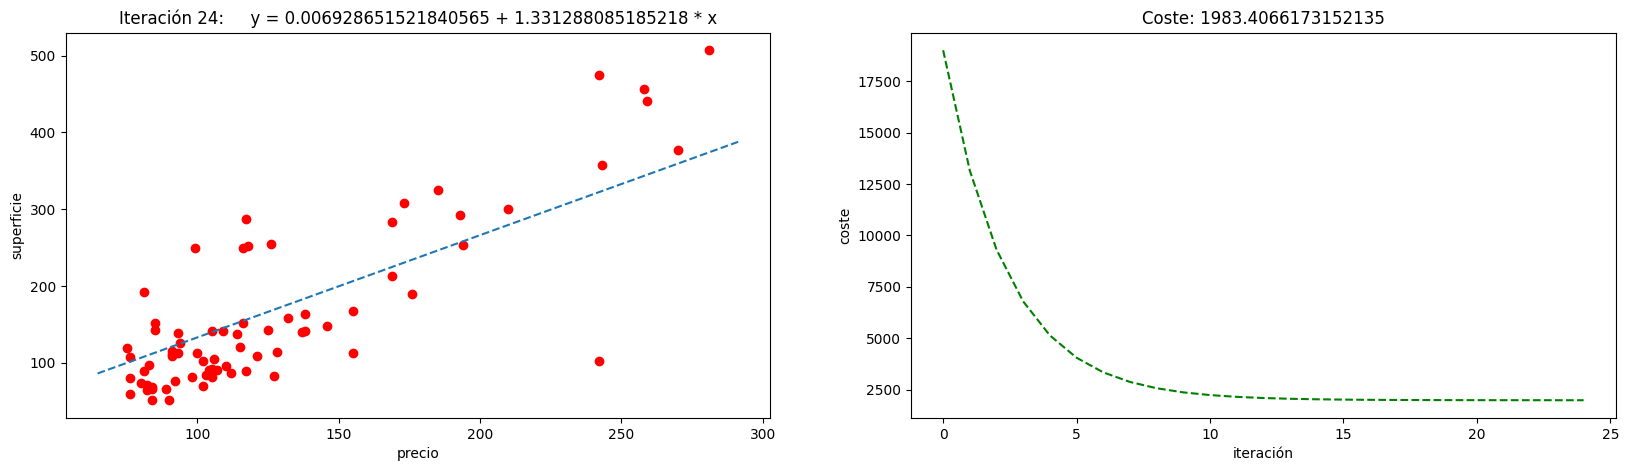

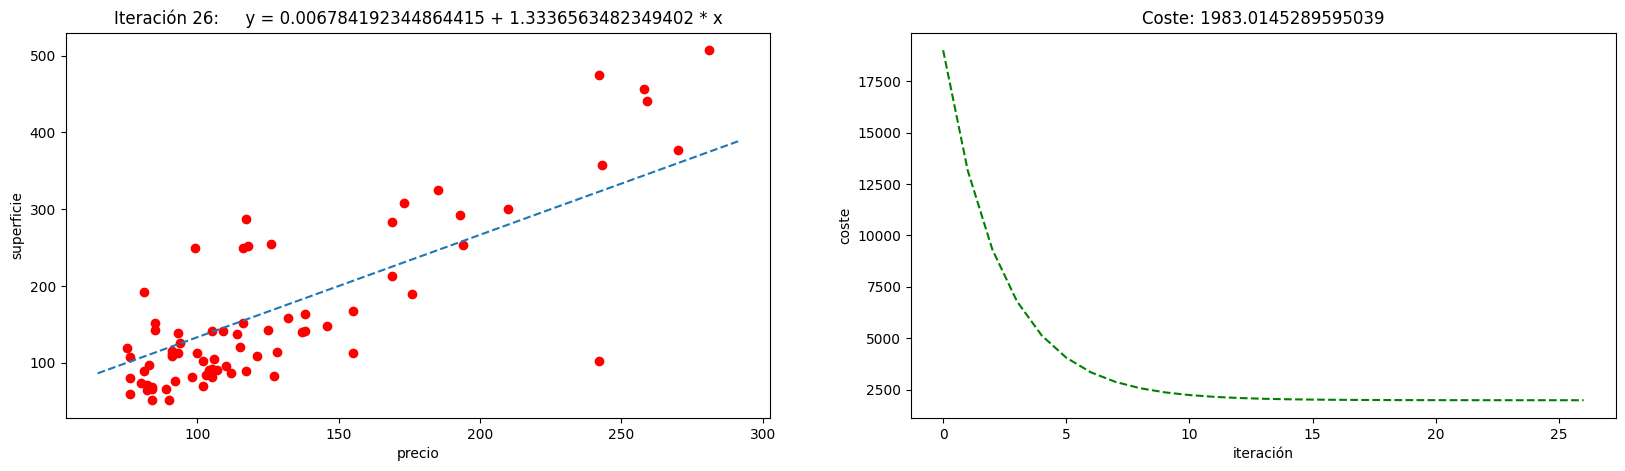

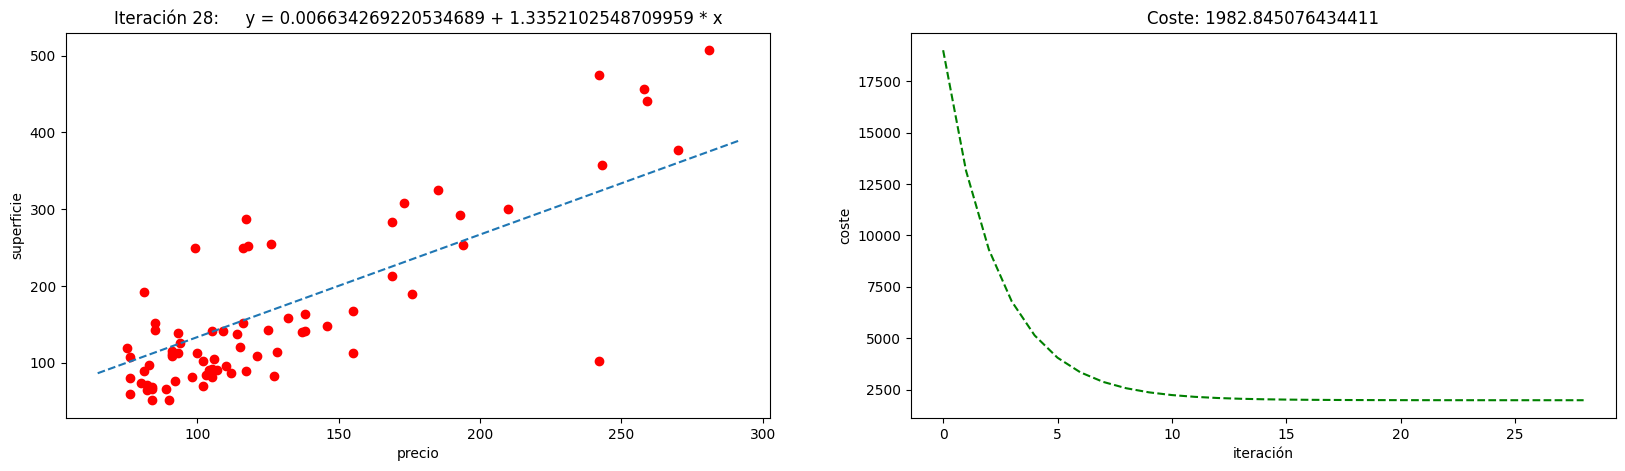

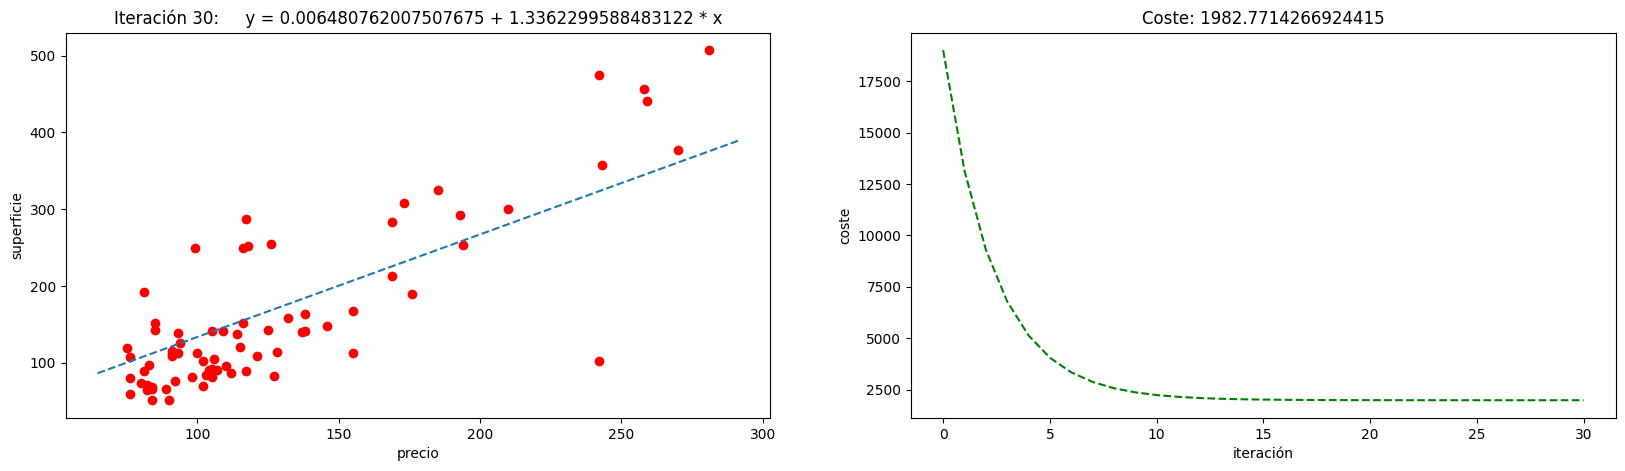

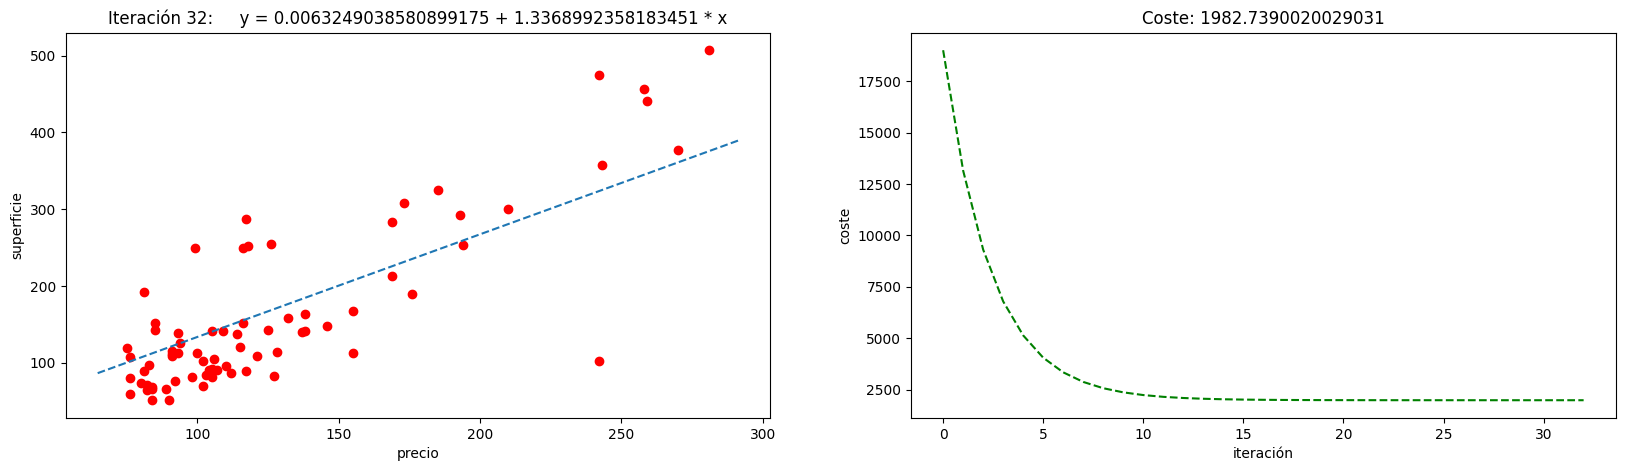

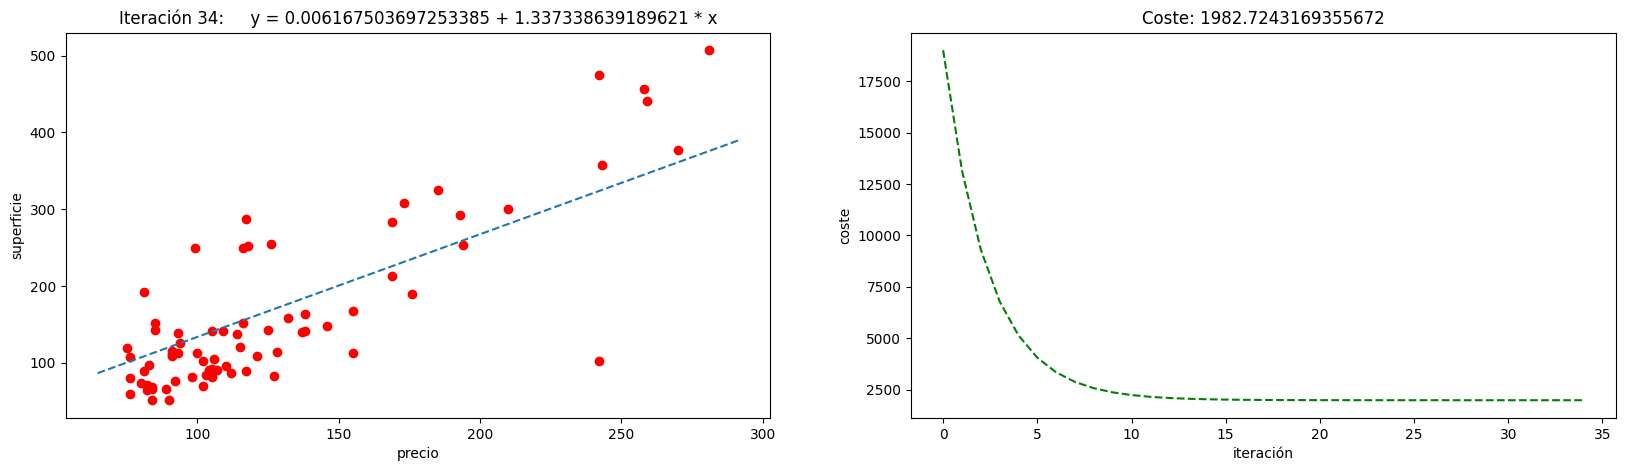

In [184]:
desc_grad(vivendas['superficie'], vivendas['prezo'], alpha = 0.00001, iteracions = 35)

> ❓ **_Pregunta 4._**  Explica brevemente y con tus palabras cómo funciona el método de descenso del gradiente. Ayúdate del problema de las viviendas y de las gráficas anteriores en tu explicación.

El descenso del gradiente busca los valores de $\theta_0$ y $\theta_1$ que hacen mínimo el error de la recta, es decir, la función de coste $J$. Para ello parte de unos valores iniciales ($\theta_0 = \theta_1 = 0$) y, en cada iteración, calcula la derivada de $J$ respecto a cada parámetro y los mueve en la dirección contraria, que es hacia donde el error baja. El tamaño de cada paso lo marca $\alpha$: si es muy grande el algoritmo puede diverger, y si es muy pequeño es seguro pero muy lento.

En el problema de las viviendas, se ve en las gráficas de la izquierda cómo la recta empieza plana y en cada iteración se va inclinando hasta atravesar la nube de puntos. En las de la derecha, el coste baja muy rápido al principio (de unos 19.000 a unos 2.200 en 10 iteraciones) y luego casi no cambia (unos 1.983 al final), porque ya está cerca del mínimo.

> ❓ **_Pregunta 5._**  Prueba a ejecutar el algoritmo variando el parámetro *alpha* ($\alpha$) y el número de iteraciones (puedes editar el script anterior o crear otro en la sección de respuestas). Analiza los resultados. ¿Cuál es la función del parámetro $\alpha$? ¿Qué sucede con valores de $\alpha$ más grandes (por ejemplo, $\alpha = 0.01$)? ¿Cuántas iteraciones dirías que son necesarias para obtener una regresión aceptable?

La función de $\alpha$ es controlar el tamaño de cada paso del descenso del gradiente, es decir, cuánto cambian $\theta_0$ y $\theta_1$ en cada iteración. Con un $\alpha$ pequeño el algoritmo avanza muy despacio: con $\alpha = 0.000001$ y 35 iteraciones el coste todavía es de unos 6.400 y la recta queda muy por debajo de los puntos, mientras que con $\alpha = 0.00001$ llega a unos 1.983. Con un $\alpha$ demasiado grande, como $\alpha = 0.01$, cada paso se pasa del mínimo: $\theta_1$ salta de positivo a negativo cada vez más lejos y el coste se dispara (más de $10^{49}$ en solo 10 iteraciones), es decir, el algoritmo diverge.

En cuanto a las iteraciones, con $\alpha = 0.00001$ el coste baja muy rápido al principio y a partir de unas 20 iteraciones casi no cambia (1.986 en la 20 y 1.983 en la 35), así que unas 20-25 iteraciones bastan para una regresión aceptable. Aun así, $\theta_0$ casi no se mueve de 0, por lo que la recta pasa prácticamente por el origen y todavía no es la óptima; para ajustarlo harían falta muchísimas más iteraciones.

In [185]:
# Versión de desc_grad sin gráficas, para probar muchas combinaciones de alpha e iteraciones
def desc_grad_sin_graficas(x, y, alpha, iteracions):
    theta0 = 0
    theta1 = 0
    m = len(x)
    for i in range(iteracions):
        pred = h(x, theta0, theta1)
        theta0 = theta0 - alpha * sum(pred-y) / m
        theta1 = theta1 - alpha * sum((pred-y) * x) / m
    return theta0, theta1, j(x, y, theta0, theta1)

# Pruebas (alpha, iteraciones)
pruebas = [(0.000001, 35), (0.000001, 100), (0.00001, 10), (0.00001, 35), (0.00001, 100), (0.0001, 35), (0.01, 10)]
for alpha, iteracions in pruebas:
    th0, th1, custo = desc_grad_sin_graficas(vivendas['superficie'], vivendas['prezo'], alpha, iteracions)
    print('alpha = {}, iteraciones = {}, theta0 = {}, theta1 = {}, coste = {}'.format(alpha, iteracions, th0, th1, custo))

alpha = 1e-06, iteraciones = 35, theta0 = 0.0041114535239259115, theta1 = 0.654547459085951, coste = 6424.210124536317
alpha = 1e-06, iteraciones = 100, theta0 = 0.006859726942037203, theta1 = 1.141787342798214, coste = 2349.2321236083594
alpha = 1e-05, iteraciones = 10, theta0 = 0.007086743523801801, theta1 = 1.1756195106278526, coste = 2233.825138449829
alpha = 1e-05, iteraciones = 35, theta0 = 0.006167503697253385, theta1 = 1.337338639189621, coste = 1982.7201922648571
alpha = 1e-05, iteraciones = 100, theta0 = 0.0009622689876398678, theta1 = 1.338209414890517, coste = 1982.6717773714192
alpha = 0.0001, iteraciones = 35, theta0 = -0.01884381397515201, theta1 = 1.3728070135305455, coste = 1993.7992595804992
alpha = 0.01, iteraciones = 10, theta0 = -5.2424641206923697e+20, theta1 = -7.812800193920052e+22, coste = 5.801281168305699e+49


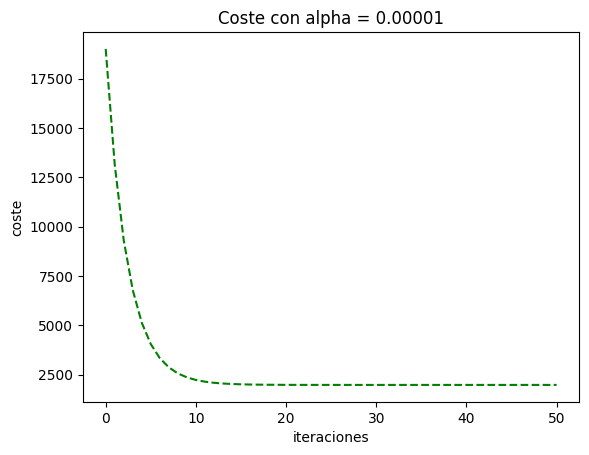

In [186]:
# Coste en función del número de iteraciones con alpha = 0.00001
iteracions = range(0, 51)
custos = [desc_grad_sin_graficas(vivendas['superficie'], vivendas['prezo'], 0.00001, n)[2] for n in iteracions]

plt.plot(iteracions, custos, '--', color="green")
plt.title("Coste con alpha = 0.00001")
plt.xlabel("iteraciones")
plt.ylabel("coste")
plt.show()

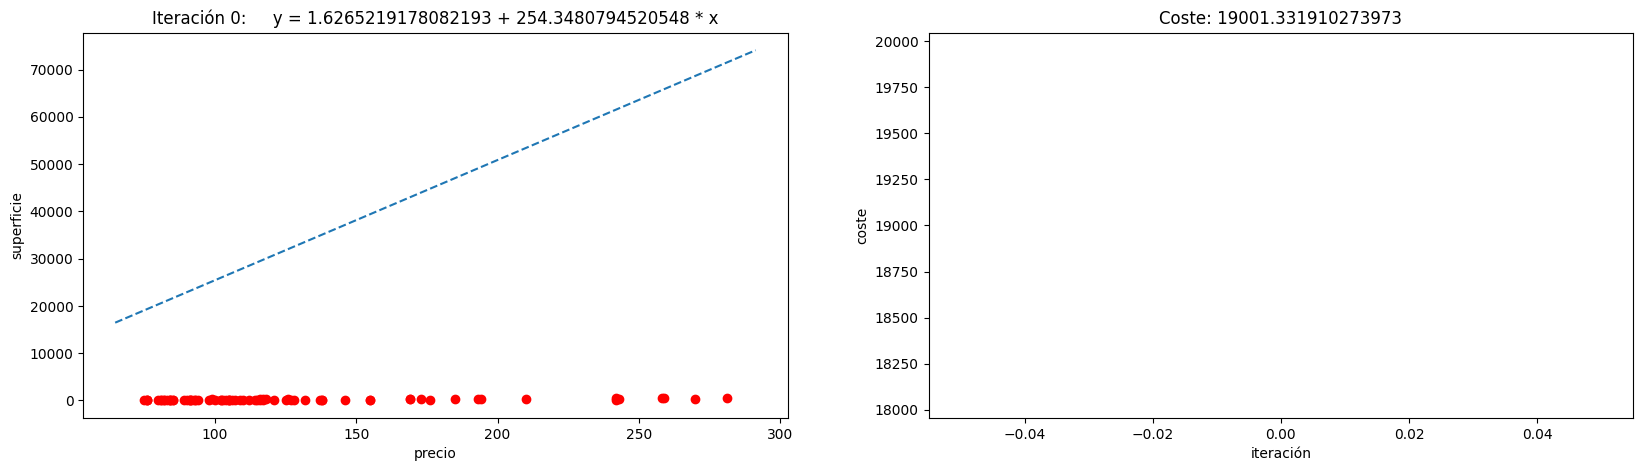

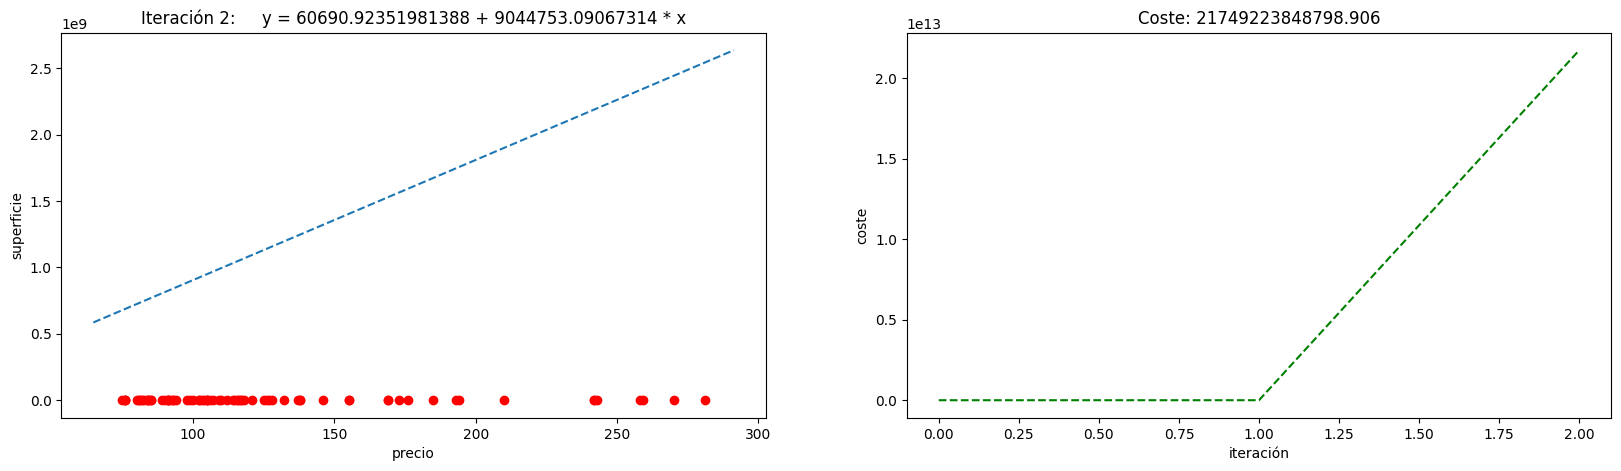

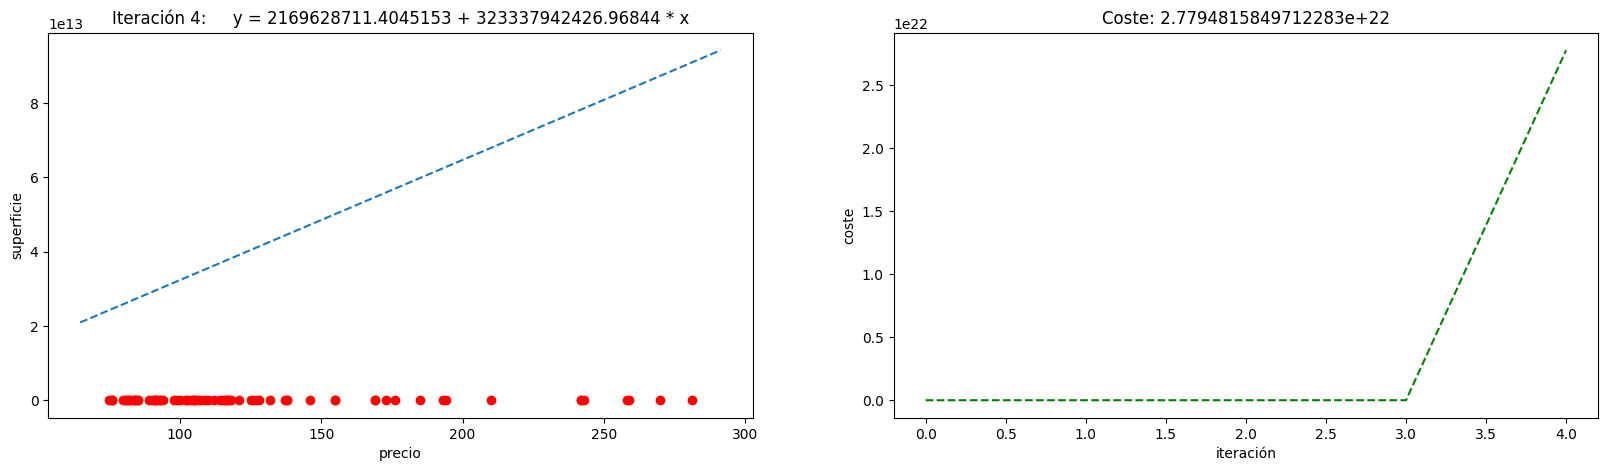

In [187]:
# Con alpha = 0.01 el algoritmo diverge
desc_grad(vivendas['superficie'], vivendas['prezo'], alpha = 0.01, iteracions = 6)

## Construcción de un modelo con `LinearRegression`

La librería `scikit-learn` nos facilita la construcción de modelos con funciones ya programadas, de forma que no es preciso que implementemos el descenso del gradiente a mano. Vamos a repetir el proceso anterior empleando ahora la clase `sklearn.linear_model.LinearRegression`. Su invocación es muy simple:

In [188]:
from sklearn.linear_model import LinearRegression  # Importamos la clase (esto solo es necesario hacerlo una vez)
from sklearn.metrics import classification_report

# Dividimos el dataset en variables predictoras y dependientes
vivendas_X = vivendas.loc[:, :'superficie'].astype(float)
vivendas_Y = vivendas.loc[:, 'prezo']

model = LinearRegression()  # Definimos el modelo
model.fit(vivendas_X, vivendas_Y)  # Ajustamos el modelo a los datos

# Resumen del modelo
coef = pd.DataFrame([model.intercept_, *model.coef_], ['(Intercept)', *vivendas_X.columns], columns=['Coefficients'])
coef

-55.577885 + 1.711149 * 185

260.98468

> ❓ **_Pregunta 6._**  Explica muy brevemente la salida de este último script. 

La salida muestra los dos coeficientes de la recta que ha calculado `LinearRegression` con todo el dataset: el término independiente (*Intercept*), $\theta_0 \approx$ -55,58, y la pendiente de la superficie, $\theta_1 \approx$ 1,711. Es decir, el modelo es precio = -55,58 + 1,711 · superficie: por cada metro cuadrado más, el precio estimado sube unos 1,71 miles de euros. Son los valores óptimos que buscaba el descenso del gradiente, que con 35 iteraciones no llegaba a alcanzar.

## Evaluación del modelo

Hasta ahora hemos visto cómo construir un modelo de regresión lineal empleando todo el dataset. Sin embargo, si lo hacemos de esta forma no tenemos manera de obtener una medida realista de cómo va a rendir el modelo con datos nuevos. Por ello, una buena práctica es dividir el dataset en dos conjuntos, uno de entrenamiento (*training*) y otro de test. Habitualmente se reserva alrededor del 70% de los datos para entrenamiento y el 30% restante para test, aunque esto son solo referencias generales. El modelo se construye empleando el conjunto de entrenamiento y posteriormente se evalúa sobre el conjunto de test.


En Python podemos crear los subconjuntos de entrenamiento y test con la ayuda de la función `train_test_split()` de la librería `scikit-learn`, para así tomar una muestra aleatoria de los datos. Para obtener todos los mismos resultados definimos una semilla con la función `random.seed()` de `NumPy`. De esta forma, no importa cuántas veces ejecutemos el script, `train_test_split` siempre hará la misma selección.

In [189]:
from sklearn.model_selection import train_test_split
SEED_VALUE = 123  # NO CAMBIES ESTE SEED, así todos tendremos los mismos resultados

np.random.seed(SEED_VALUE)
vivendas_train, vivendas_test = train_test_split(vivendas, test_size=0.3, random_state=SEED_VALUE)

print('Tamaño train: {}'.format(vivendas_train.shape[0]))
print('Tamaño test: {}'.format(vivendas_test.shape[0]))

Tamaño train: 51
Tamaño test: 22


Construimos el modelo empleando solo el conjunto de entrenamiento:

In [190]:
# Dividimos el dataset en variables predictoras y dependientes
vivendas_train_X = vivendas_train.loc[:, :'superficie'].astype(float)
vivendas_train_Y = vivendas_train.loc[:, 'prezo']

model = LinearRegression()  # Definimos el modelo
np.random.seed(SEED_VALUE)
model.fit(vivendas_train_X, vivendas_train_Y)  # Ajustamos el modelo a los datos

# Resumen del modelo
coef = pd.DataFrame([model.intercept_, *model.coef_], ['(Intercept)', *vivendas_train_X.columns], columns=['Coefficients'])
coef

,Coefficients
(Intercept),-34.426839
superficie,1.510870


Ahora predecimos los valores de las viviendas del conjunto de validación con la ayuda de la función `.predict()`:

In [191]:
# Dividimos el dataset en variables predictoras y dependientes
vivendas_test_X = vivendas_test.loc[:, :'superficie'].astype(float)
vivendas_test_Y = vivendas_test.loc[:, 'prezo']

np.random.seed(SEED_VALUE)
predicions = model.predict(vivendas_test_X)

La función anterior simplemente obtiene los precios de las viviendas del conjunto de test a partir de la función de regresión lineal que ajusta el modelo. Observa que otra forma de hacer esta predicción es empleando la función $h_\theta(x)$ que definimos antes indicando los coeficientes $\theta_0$ y $\theta_1$ de nuestro modelo:

In [192]:
predicions2 = h(vivendas_test_X, th0=coef['Coefficients']['(Intercept)'], th1=coef['Coefficients']['superficie'])

Las predicciones de los conjuntos `predicions` y `predicions2` deberían coincidir:

In [193]:
print('Predicciones obtenidas con la función .predict():')
print(predicions)
print()
print('Predicciones obtenidas con la función h:')
print(predicions2.to_numpy()[:, 0])

Predicciones obtenidas con la función .predict():
[257.17108422 119.68190805 119.68190805 332.71458762 258.68195429
 165.00801008 127.23625839 331.20371755  80.39928628 140.834089
 121.19277811  92.48624682 282.85587538 124.21451825 142.34495906
 125.72538832 142.34495906 220.91020259 131.76886859 139.32321893
 356.8885087   86.44276655]

Predicciones obtenidas con la función h:
[257.17108422 119.68190805 119.68190805 332.71458762 258.68195429
 165.00801008 127.23625839 331.20371755  80.39928628 140.834089
 121.19277811  92.48624682 282.85587538 124.21451825 142.34495906
 125.72538832 142.34495906 220.91020259 131.76886859 139.32321893
 356.8885087   86.44276655]


Como disponemos de las predicciones de los precios de las viviendas del conjunto de test y también conocemos sus precios reales, ahora podemos evaluar el rendimiento de nuestro modelo. Por ejemplo, podemos emplear de nuevo el error cuadrático medio: 

In [194]:
e_cadratico = ecm(vivendas_test_Y, predicions)
print(e_cadratico)

1775.6429474014146


El problema del error cuadrático medio es que no resulta un indicador muy intuitivo. Sin embargo, podemos calcular su raíz cuadrada para obtener una estimación del error en miles de euros:

In [195]:
np.sqrt(e_cadratico)

np.float64(42.13837855686209)

Otra posibilidad es emplear el índice de correlación entre los datos reales y las predicciones:

In [196]:
vivendas_test_Y.corr(pd.Series(predicions, vivendas_test_Y.index))

np.float64(0.9160621867265677)

Como vemos, el índice de correlación es prácticamente 1, por lo que podemos afirmar que ambos vectores están muy correlacionados positivamente. Esto es señal de que estamos realizando buenas predicciones.

> ❓ **_Pregunta 7._**  ¿Por qué no sería adecuado evaluar el rendimiento de nuestro modelo empleando los mismos datos con los que lo entrenamos?

Porque el modelo ha calculado sus coeficientes precisamente para equivocarse lo menos posible con los datos de entrenamiento, así que el error sobre esos mismos datos sería demasiado optimista y no diría nada de cómo se comporta con viviendas nuevas, que es para lo que queremos el modelo.

Por eso se reserva un conjunto de test que el modelo no ve durante el entrenamiento. Al predecir esas viviendas y comparar con sus precios reales, se obtiene una medida más realista de su rendimiento con datos no vistos.

## Identificación de valores atípicos (*outliers*)

Los valores atípicos, anómalos u *outliers* son instancias de nuestro conjunto de datos que no siguen la tendencia habitual del dataset, siendo numéricamente distantes al resto de los datos. En otras palabras, son instancias que parecen inconsistentes con el resto de los valores del dataset. Debemos evitar que nuestro conjunto de entrenamiento presente estos datos atípicos ya que pueden deteriorar mucho la calidad de nuestros modelos.

Vamos a ver un ejemplo sencillo de cómo identificar *outliers* y analizaremos su impacto en la calidad del modelo del precio de las viviendas. Ten en cuenta que esta es una etapa habitual en el preprocesado de los datos. Nosotros excepcionalmente vamos a abordarla ahora, tras tener un modelo, con fines ilustrativos.

Los diagramas de caja, o *boxplots*, son gráficos basados en cuartiles que nos permiten visualizar la distribución del conjunto de datos para cada una de las variables. En Python podemos visualizarlos con la función `boxplot()` de `matplotlib`:

/var/folders/zg/g2xkvjcn3fl94hsj4jlpl7y40000gn/T/ipykernel_10320/3394143401.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(vivendas_train, labels=vivendas_train.columns)


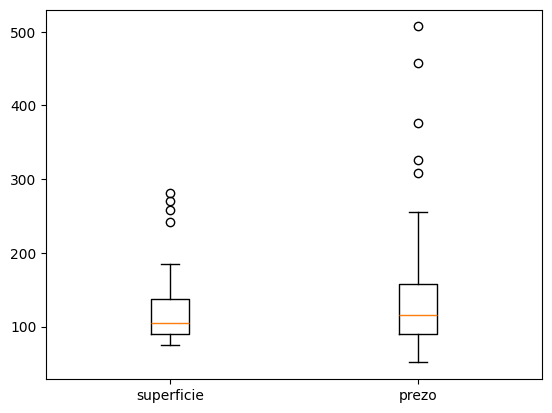

In [197]:
box = plt.boxplot(vivendas_train, labels=vivendas_train.columns)

Dentro de la caja se encuentra el 50% de los datos. Los datos más atípicos (círculos) están fuera de los brazos de la caja. Vemos que ambas variables presentan unos pocos *outliers* en su distribución. Estos *outliers* se conocen como univariados porque están presentes en la distribución de una sola variable. Podemos saber los valores de esos *outliers* de la siguiente forma:

In [198]:
out_superficie = box["fliers"][0].get_data()[1]
out_prezo = box["fliers"][1].get_data()[1]

print("Outliers en la variable 'superficie': {}".format(out_superficie))
print("Outliers en la variable 'prezo': {}".format(out_prezo))

Outliers en la variable 'superficie': [258. 270. 242. 281.]
Outliers en la variable 'prezo': [308.53 457.11 376.51 325.61 507.09]


Así conocemos las superficies y precios atípicos. Ahora bien, que un ejemplo sea *outlier* en alguna de las dimensiones no implica que sea realmente un dato atípico en nuestro problema. Por ejemplo, que una vivienda tenga una superficie de 281 metros cuadrados puede ser un valor atípico de la dimensión Superficie si la mayoría de las viviendas son pequeñas en el dataset. Del mismo modo, una vivienda que cueste cerca de 500.000 euros puede ser atípica si el precio medio de la vivienda es mucho inferior.

Los *outliers* de los que realmente nos tenemos que preocupar son aquellos *outliers* multivariados, es decir, que disten de la tendencia en las dos dimensiones, superficie-precio. Existen métodos de identificación de outliers en más de una dimensión pero, debido a su complejidad, quedan fuera de esta práctica. Puesto que nuestro problema cuenta con pocas instancias, podemos hacer una inspección visual y manual:

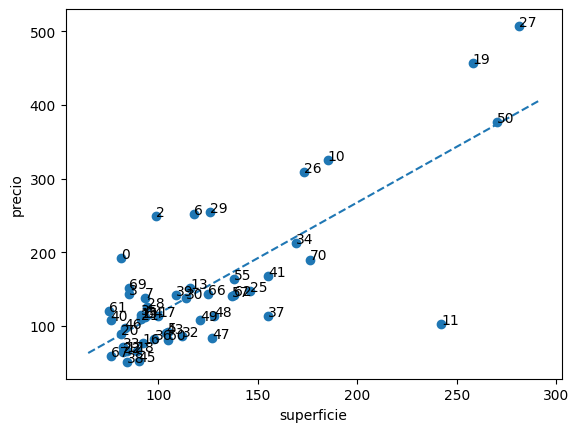

In [199]:
# Creamos el entorno
fig = plt.figure()  # Creamos una figura (contenedor para elementos a dibujar)
ax = fig.add_subplot(111, projection='rectilinear')  # Añadimos un Axes a la figura (contiene los elementos del dibujo)
plt.xlabel("superficie")  # Nombramos los ejes
plt.ylabel("precio")

# Dibujamos el scatter
ax.scatter(vivendas_train['superficie'], vivendas_train['prezo'])

# Creamos y mostramos la recta
line_x_vals = np.array(ax.get_xlim())
line_y_vals = coef['Coefficients']['(Intercept)'] + coef['Coefficients']['superficie'] * line_x_vals
ax.plot(line_x_vals, line_y_vals, '--')

# Imprimimos los identificadores
for i in vivendas_train.index:
    ax.text(vivendas_train['superficie'][i], vivendas_train['prezo'][i], i)

plt.show()

Si nos fijamos en el gráfico de dispersión, existe un valor mucho más distante de la recta de regresión que el resto:

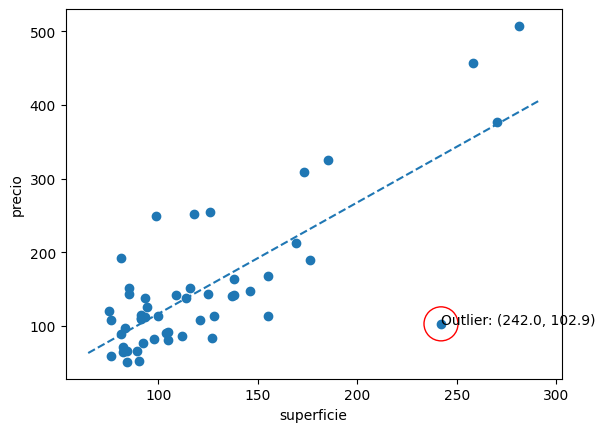

In [200]:
# Creamos el entorno
fig = plt.figure()  # Creamos una figura (contenedor para elementos a dibujar)
ax = fig.add_subplot(111, projection='rectilinear')  # Añadimos un Axes a la figura (contiene los elementos del dibujo)
plt.xlabel("superficie")  # Nombramos los ejes
plt.ylabel("precio")

# Dibujamos el scatter
ax.scatter(vivendas_train['superficie'], vivendas_train['prezo'])

# Mostramos la recta
ax.plot(line_x_vals, line_y_vals, '--')

# Marcamos el outlier
outlier_id = 11
outlier = vivendas_train.loc[outlier_id]
ax.scatter(outlier['superficie'], outlier['prezo'], s=600, facecolors='none', edgecolors='r')
ax.text(outlier['superficie'], outlier['prezo'],
        'Outlier: ({}, {})'.format(outlier['superficie'], outlier['prezo']))
plt.show()

Vamos a ver si podemos mejorar la calidad del modelo prescindiendo de este dato atípico. Lo eliminamos del conjunto de entrenamiento y entrenamos un nuevo modelo:

In [201]:
# Eliminamos el outlier del conjunto
vivendas_train = vivendas_train.drop(outlier_id)

# Dividimos el dataset en variables predictoras y dependientes
vivendas_train_X = vivendas_train.loc[:, :'superficie'].astype(float)
vivendas_train_Y = vivendas_train.loc[:, 'prezo']

new_model = LinearRegression()  # Definimos un nuevo modelo
new_model.fit(vivendas_train_X, vivendas_train_Y)  # Ajustamos el nuevo modelo a los datos

# Resumen del modelo
new_coef = pd.DataFrame([new_model.intercept_, *new_model.coef_], ['(Intercept)', *vivendas_train_X.columns], columns=['Coefficients'])
new_coef

,Coefficients
(Intercept),-59.680167
superficie,1.759946


Graficamos para ver la diferencia entre el nuevo modelo sin el outlier y el viejo:

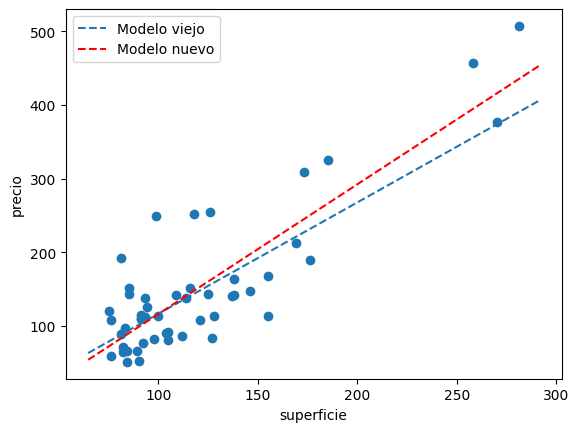

In [202]:
# Creamos el entorno
fig = plt.figure()  # Creamos una figura (contenedor para elementos a dibujar)
ax = fig.add_subplot(111, projection='rectilinear')  # Añadimos un Axes a la figura (contiene los elementos del dibujo)
plt.xlabel("superficie")  # Nombramos los ejes
plt.ylabel("precio")

# Dibujamos el scatter
ax.scatter(vivendas_train['superficie'], vivendas_train['prezo'])

# Creamos y mostramos la recta antigua
line_x_vals = np.array(ax.get_xlim())
line_y_vals = coef['Coefficients']['(Intercept)'] + coef['Coefficients']['superficie'] * line_x_vals
ax.plot(line_x_vals, line_y_vals, '--', label='Modelo viejo')

# Creamos y mostramos la recta nueva
line_y_vals = new_coef['Coefficients']['(Intercept)'] + new_coef['Coefficients']['superficie'] * line_x_vals
ax.plot(line_x_vals, line_y_vals, '--', color='r', label='Modelo nuevo')

ax.legend()  # Hacemos que se muestren las labels

plt.show()

Realizamos de nuevo la predicción sobre el conjunto de test y evaluamos el rendimiento:

In [203]:
novas_predicions = new_model.predict(vivendas_test_X)
e_cadratico_novo = ecm(vivendas_test_Y, novas_predicions)

print(np.sqrt(e_cadratico_novo))
vivendas_test_Y.corr(pd.Series(novas_predicions, vivendas_test_Y.index))

37.012141302915026


np.float64(0.9160621867265676)

> ❓ **_Pregunta 8._**  Analiza brevemente el impacto del *outlier* en el modelo de regresión.

El *outlier* es la vivienda de 242 m² que cuesta solo 102,9 miles de euros. Como es muy grande pero muy barata, no sigue la tendencia del resto y hace que la recta quede más plana de lo que debería. Al quitarla y volver a entrenar, la recta se inclina más (la pendiente pasa de 1,51 a 1,76) y se ajusta mejor al resto de puntos.

El nuevo modelo también predice mejor: con el mismo conjunto de test, el error baja de unos 42 a unos 37 miles de euros. La correlación entre los precios reales y los predichos no cambia (0,92), porque solo dice si las predicciones siguen la tendencia de los datos, no cuánto se equivocan.

**************************************************************

# Respuestas al cuestionario

**RECUERDA:** No olvides escribir tu nombre y apellidos en la segunda celda del presente documento.

**Pregunta 1**


**Pregunta 2**



**Pregunta 3**



**Pregunta 4**



**Pregunta 5**



**Pregunta 6**



**Pregunta 7**



**Pregunta 8**



**************************************************************

# Modelado de un problema de regresión multivariante

## Enunciado

El problema sobre el que acabamos de trabajar es un "ejemplo de juguete". En la realidad, resultaría difícil poder predecir con exactitud el precio de una vivienda teniendo en cuenta solo una variable (en este caso, la superficie). Lo más probable es que otros factores contribuyan a estimar un buen precio para los inmuebles. Algunos ejemplos de otras variables continuas que se podrían emplear son su antigüedad, la distancia al centro urbano más próximo, el coste de la vida en la ciudad, región o país donde se ubica, etc.

Hay muchos portales de donde puedes sacar datos. Por ejemplo Kaggle, la mayor comunidad de ciencia de datos y aprendizaje automático online. Aquí tienes algunos enlaces que puedes consultar:

- [datasets "friendly" en Kaggle](https://www.kaggle.com/rtatman/fun-beginner-friendly-datasets)
- [otros datasets sencillitos pensados para regresión](https://people.sc.fsu.edu/~jburkardt/datasets/regression/regression.html)

Vamos a trabajar con el dataset 80 cereals (https://www.kaggle.com/datasets/crawford/80-cereals). Carga el fichero cereal.csv y pon en práctica tus conocimientos de regresión lineal. Escoge como variables predictoras aquellas que pienses que pueden estar linealmente correlacionadas con la variable que quieres predecir (*rating*). El único requisito obligatorio es **emplear exactamente DOS variables predictoras** en el entrenamiento del modelo de regresión.

Asegúrate de comprender bien el problema y la información que estás manejando. Haz un breve estudio de tus datos, incluyendo gráficas y comentarios propios. De ser preciso, aplica las etapas de preprocesado que consideres, pero cuidado porque quizás te implique hacer un preprocesado demasiado complejo, para el que no estás preparado aún. Luego, obtén el modelo y evalúa su rendimiento. No pasa nada si finalmente no hay una buena correlación entre las variables predictoras y la variable objetivo y el modelo realiza malas predicciones. La finalidad de este ejercicio es abordar un problema real y que realices un buen procedimiento de análisis de datos en base a lo aprendido.

Obtén un modelo siguiendo las buenas prácticas que hemos ido viendo.

**************************************************************

## Respuesta

Vamos a predecir el *rating* de los cereales usando dos variables predictoras.

In [204]:
cereais = pd.read_csv('cereal.csv', delimiter=',', header=0)  # Cargamos el csv
cereais.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      77 non-null     str    
 1   mfr       77 non-null     str    
 2   type      77 non-null     str    
 3   calories  77 non-null     int64  
 4   protein   77 non-null     int64  
 5   fat       77 non-null     int64  
 6   sodium    77 non-null     int64  
 7   fiber     77 non-null     float64
 8   carbo     77 non-null     float64
 9   sugars    77 non-null     int64  
 10  potass    77 non-null     int64  
 11  vitamins  77 non-null     int64  
 12  shelf     77 non-null     int64  
 13  weight    77 non-null     float64
 14  cups      77 non-null     float64
 15  rating    77 non-null     float64
dtypes: float64(5), int64(8), str(3)
memory usage: 9.8 KB


Hay 77 cereales y 16 variables, sin valores nulos. Tres columnas son de texto (`name`, `mfr` y `type`) y el resto son numéricas: la información nutricional de cada cereal y su `rating`, que es lo que queremos predecir.

In [205]:
cereais.describe()

,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
count,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000
mean,106.883117,2.545455,1.012987,159.675325,2.151948,14.597403,6.922078,96.077922,28.246753,2.207792,1.029610,0.821039,42.665705
std,19.484119,1.094790,1.006473,83.832295,2.383364,4.278956,4.444885,71.286813,22.342523,0.832524,0.150477,0.232716,14.047289
min,50.000000,1.000000,0.000000,0.000000,0.000000,-1.000000,-1.000000,-1.000000,0.000000,1.000000,0.500000,0.250000,18.042851
25%,100.000000,2.000000,0.000000,130.000000,1.000000,12.000000,3.000000,40.000000,25.000000,1.000000,1.000000,0.670000,33.174094
50%,110.000000,3.000000,1.000000,180.000000,2.000000,14.000000,7.000000,90.000000,25.000000,2.000000,1.000000,0.750000,40.400208
75%,110.000000,3.000000,2.000000,210.000000,3.000000,17.000000,11.000000,120.000000,25.000000,3.000000,1.000000,1.000000,50.828392
max,160.000000,6.000000,5.000000,320.000000,14.000000,23.000000,15.000000,330.000000,100.000000,3.000000,1.500000,1.500000,93.704912


Algunos cereales tienen -1 en `carbo`, `sugars` o `potass`, que significa que falta el dato. Como son solo 3, los quitamos.

In [206]:
# Buscamos los cereales con algún -1
for i in cereais.index:
    if cereais['carbo'][i] < 0 or cereais['sugars'][i] < 0 or cereais['potass'][i] < 0:
        print(i, cereais['name'][i])

cereais = cereais.drop([4, 20, 57])  # Los quitamos

4 Almond Delight
20 Cream of Wheat (Quick)
57 Quaker Oatmeal


In [207]:
# Correlación de cada variable numérica con rating
cereais.loc[:, 'calories':'rating'].corr()['rating']

calories   -0.693785
protein     0.467162
fat        -0.405050
sodium     -0.383012
fiber       0.603411
carbo       0.055941
sugars     -0.755955
potass      0.415782
vitamins   -0.214481
shelf       0.051040
weight     -0.300461
cups       -0.222504
rating      1.000000
Name: rating, dtype: float64

Escogemos `sugars` (-0,76) y `fiber` (0,60), que están entre las más correlacionadas con `rating`. No usamos `calories` (-0,69) porque está bastante relacionada con `sugars` y repetiría casi la misma información:

In [208]:
cereais['sugars'].corr(cereais['calories'])  # Correlación entre sugars y calories

np.float64(0.569120535229035)

<Axes: xlabel='sugars', ylabel='rating'>

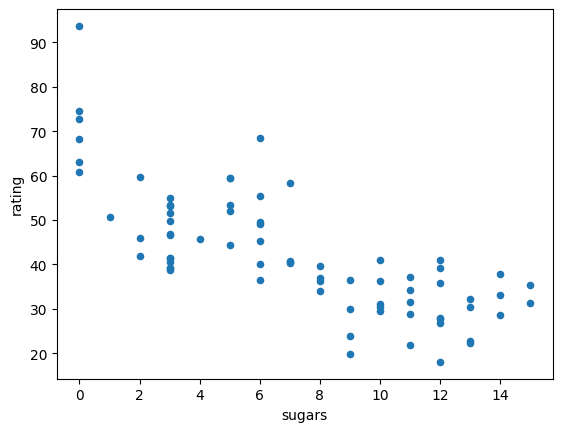

In [209]:
cereais.plot(kind='scatter', x='sugars', y='rating')

<Axes: xlabel='fiber', ylabel='rating'>

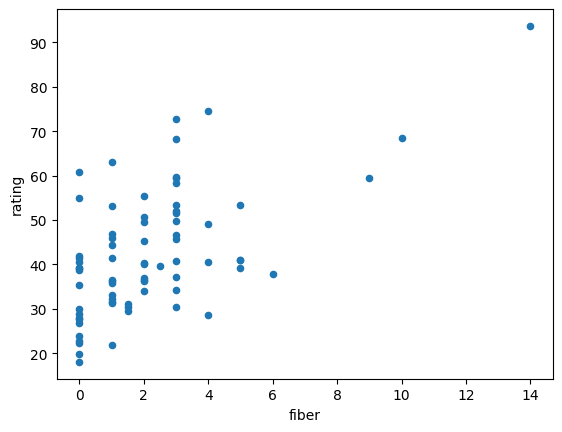

In [210]:
cereais.plot(kind='scatter', x='fiber', y='rating')

Con más azúcar el *rating* baja de forma bastante clara, y con más fibra sube, aunque con los puntos más dispersos.

In [211]:
# Separamos train (70%) y test (30%)
np.random.seed(SEED_VALUE)
cereais_train, cereais_test = train_test_split(cereais, test_size=0.3, random_state=SEED_VALUE)

# Entrenamos el modelo con sugars y fiber
cereais_train_X = cereais_train.loc[:, ['sugars', 'fiber']].astype(float)
cereais_train_Y = cereais_train.loc[:, 'rating']

modelo_cereais = LinearRegression()
np.random.seed(SEED_VALUE)
modelo_cereais.fit(cereais_train_X, cereais_train_Y)

coef_cereais = pd.DataFrame([modelo_cereais.intercept_, *modelo_cereais.coef_], ['(Intercept)', *cereais_train_X.columns], columns=['Coefficients'])
coef_cereais

,Coefficients
(Intercept),50.125704
sugars,-1.996680
fiber,2.925885


In [ ]:
# Evaluamos con el conjunto de test
cereais_test_X = cereais_test.loc[:, ['sugars', 'fiber']].astype(float)
cereais_test_Y = cereais_test.loc[:, 'rating']

np.random.seed(SEED_VALUE)
predicions_cereais = modelo_cereais.predict(cereais_test_X)

print(np.sqrt(ecm(cereais_test_Y, predicions_cereais)))  # Raíz del error cuadrático
cereais_test_Y.corr(pd.Series(predicions_cereais, cereais_test_Y.index))  # Correlación

Los cereales con más azúcar tienen peor *rating* y los que tienen más fibra, mejor. El modelo queda como rating = 50,13 - 2,00 · sugars + 2,93 · fiber. En test, la raíz del error es de unos 4,2 puntos y la correlación de 0,91, así que predice bastante bien con solo dos variables.

**************************************************************